# Integração ITBI–mobilidade

As seções iniciais preservam o diagnóstico em linha reta e o complemento histórico de Metrô/BRT/VLT. A seção 7 incorpora a referência de 2024 das quatro modalidades, com pontos BRS reais no GTFS oficial de 2024. Essa referência alimenta as perguntas 5–7 do artigo; o corredor BRS não é usado como ponto de embarque.

In [1]:
from pathlib import Path
import sys
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks": RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path: sys.path.insert(0, str(RAIZ))
from ambiente import garantir_dependencias
garantir_dependencias()

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from IPython.display import display

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
import sys
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from analise_mobilidade import (preparar, comparar, tabela_artigo, tabela_niveis,
    dispersao, formatar_tabela, evolucao_proximidade, figura_proximidade, figura_comparacao)

PASTA = RAIZ / "data" / "processed"
ENTRADA = PASTA / "itbi_residencial_2011_2024_geocodificado_completo.csv.gz"
if not ENTRADA.is_file(): ENTRADA=PASTA/"itbi_residencial_2011_2024_geocodificado_completo.csv"
CAMADA = PASTA / "mobilidade" / "pontos_transporte.gpkg"
for arquivo in [ENTRADA,CAMADA]:
    if not arquivo.is_file():
        raise FileNotFoundError(f"Entrada ausente: {arquivo.name}. Execute 01 e 02 conforme o README.")

## 1. Validação das entradas

Usamos todas as transações da base de alta precisão com ano entre 2011 e 2024. Os preços são preservados como exportados pelo notebook 01. A classificação de preços para o artigo será aplicada apenas depois da integração. Um grupo geográfico deve apontar para um único par de coordenadas.

In [3]:
itbi = pd.read_csv(ENTRADA,low_memory=False)
if "qualidade_geocodificacao" in itbi:
    itbi = itbi.loc[itbi["qualidade_geocodificacao"].eq("alta_precisao")].copy()
necessarias={"id_transacao","id_grupo_geografico","ano","mes","nm_bairro_norm",
             "ds_imovel_tipologia","area","valor_transacoes","valor_m2","lat_analise","lon_analise"}
if necessarias-set(itbi):
    raise ValueError(f"Colunas ausentes no ITBI: {sorted(necessarias-set(itbi))}")
assert itbi.id_transacao.notna().all() and itbi.id_transacao.is_unique
for col in ["ano","area","valor_m2","valor_transacoes","lat_analise","lon_analise"]:
    itbi[col]=pd.to_numeric(itbi[col],errors="coerce")
assert itbi.ano.between(2011,2024).all()
assert itbi.id_grupo_geografico.notna().all()
assert np.isfinite(itbi[["lat_analise","lon_analise"]].to_numpy()).all()
assert itbi.lat_analise.between(-23.5,-22.5).all() and itbi.lon_analise.between(-44,-42.5).all()
assert (itbi.groupby("id_grupo_geografico")[["lat_analise","lon_analise"]].nunique()<=1).all().all()
transportes=gpd.read_file(CAMADA).to_crs(epsg=31983)
assert transportes.geometry.notna().all() and transportes.geometry.geom_type.eq("Point").all()
transportes["ano_inicio"]=pd.to_numeric(transportes.ano_inicio,errors="coerce")
display(pd.DataFrame({"transacoes":[len(itbi)],"grupos_geograficos":[itbi.id_grupo_geografico.nunique()]}))
display(transportes.groupby("modal").agg(registros=("nome","size"),anos_conhecidos=("ano_inicio","count")))

,transacoes,grupos_geograficos
0,320104,62329


,registros,anos_conhecidos
modal,,
BRT,156,153
Metrô,41,41
VLT,31,30


## 2. Cálculo das distâncias

Uma observação por grupo geográfico e ano evita repetir consultas. Para pontos, calcula-se o vizinho mais próximo; para o BRS, a distância mínima à união dos corredores já em operação. O ano de operação deve ser conhecido e não posterior à transação. Sem rede datada disponível, a distância fica ausente.

Colunas `dist_*_sem_ano_m` registram a distância aos objetos sem data. Se a distância à rede datada for maior que o limiar, mas um objeto sem data estiver dentro dele, a observação é indeterminada e não é classificada como distante. Esta regra é recalculada em cada limiar de sensibilidade.

In [4]:
import shapely
locais=itbi[["ano","id_grupo_geografico","lat_analise","lon_analise"]].drop_duplicates().reset_index(drop=True)
assert not locais.duplicated(["ano","id_grupo_geografico"]).any()
geo=gpd.GeoDataFrame(locais,geometry=gpd.points_from_xy(locais.lon_analise,locais.lat_analise),crs=4326).to_crs(epsg=31983)
xy=np.column_stack([geo.geometry.x,geo.geometry.y])
modalidades={"Metrô":"dist_metro_m","BRT":"dist_brt_m","VLT":"dist_vlt_m","BRS (corredor)":"dist_brs_m"}
brs=gpd.read_file(PASTA/"mobilidade/brs_preparado.gpkg").to_crs(epsg=31983)
brs["ano_inicio"]=pd.to_numeric(brs.ano_inicio_utilizavel,errors="coerce")
for modal,col in modalidades.items():
    rede=brs if modal=="BRS (corredor)" else transportes.loc[transportes.modal.eq(modal)]
    assert rede.geometry.notna().all() and rede.geometry.is_valid.all()
    locais[col]=np.nan
    desconhecida=col.removesuffix("_m")+"_sem_ano_m"
    locais[desconhecida]=np.nan
    sem_data=rede.loc[rede.ano_inicio.isna()]
    if len(sem_data):locais[desconhecida]=shapely.distance(geo.geometry.array,sem_data.geometry.union_all())
    for ano in sorted(locais.ano.unique()):
        disponiveis=rede.loc[rede.ano_inicio.le(ano)]
        if disponiveis.empty:continue
        filtro=locais.ano.eq(ano)
        if modal=="BRS (corredor)":
            locais.loc[filtro,col]=shapely.distance(geo.loc[filtro].geometry.array,disponiveis.geometry.union_all())
        else:
            arvore=cKDTree(np.column_stack([disponiveis.geometry.x,disponiveis.geometry.y]))
            locais.loc[filtro,col]=arvore.query(xy[filtro])[0]
    assert locais[col].dropna().ge(0).all()
colunas=[c for c in locais if c.startswith("dist_")]
itbi_com_distancias=itbi.merge(locais[["ano","id_grupo_geografico",*colunas]],on=["ano","id_grupo_geografico"],how="left",validate="many_to_one")
assert len(itbi_com_distancias)==len(itbi) and itbi_com_distancias.id_transacao.is_unique
pd.testing.assert_frame_equal(itbi_com_distancias[itbi.columns].reset_index(drop=True),itbi.reset_index(drop=True))
SAIDA=PASTA/"itbi_com_distancias.csv.gz"
itbi_com_distancias.to_csv(SAIDA,index=False)
display(itbi_com_distancias[colunas].agg(["count","min","max"]).round(2))

,dist_metro_m,dist_metro_sem_ano_m,dist_brt_m,dist_brt_sem_ano_m,dist_vlt_m,dist_vlt_sem_ano_m,dist_brs_m,dist_brs_sem_ano_m
count,320104.00,0.0,304447.00,320104.00,206920.00,320104.00,320104.00,320104.00
min,6.34,NaN,4.79,97.96,13.19,140.76,0.01,119.65
max,39954.31,NaN,35364.89,26405.27,52379.47,54378.02,50537.89,54802.29


## 3. Diagnóstico de distância reta (não é o resultado principal)

Preços em reais de dezembro de 2024 pelo número-índice mensal oficial do IPCA. As tabelas a 500 m abaixo preservam uma referência geográfica para auditoria. Não medem caminhada. A análise principal do artigo é a seção 6, com 800 m por rede de pedestres e sensibilidade a 500, 1.000 e 1.500 m.

Resumo territorial exportado para: .\data\processed\resumo_comparacao_mobilidade.csv


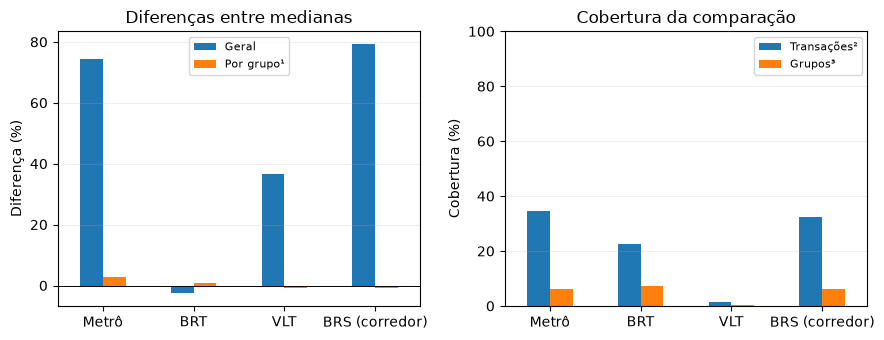

In [5]:
dados,amostra=preparar(itbi_com_distancias)
resumo,grupos_por_modal=comparar(amostra)
# O gráfico mostra o contraste perto/longe; os CSVs mantêm o detalhamento completo.
print("Resumo territorial exportado para:", PASTA/"resumo_comparacao_mobilidade.csv")
resumo.to_csv(PASTA/"resumo_comparacao_mobilidade.csv",index=False)
figura_comparacao(resumo)
plt.show()
# Atualiza a saída compactada usada no artigo.
itbi_com_distancias.to_csv(PASTA/"itbi_com_distancias.csv.gz",index=False,
                          compression={"method":"gzip","mtime":0})

## 4. Proximidade ao longo do tempo

O denominador é o total de transações com distância válida para cada modalidade e ano, antes do filtro de preços. Ausências não são classificadas como distantes. A figura descreve transações observadas, não cobertura de residências nem evolução dos preços.

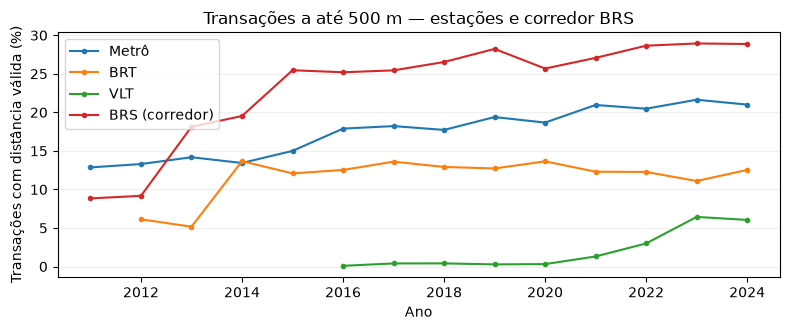

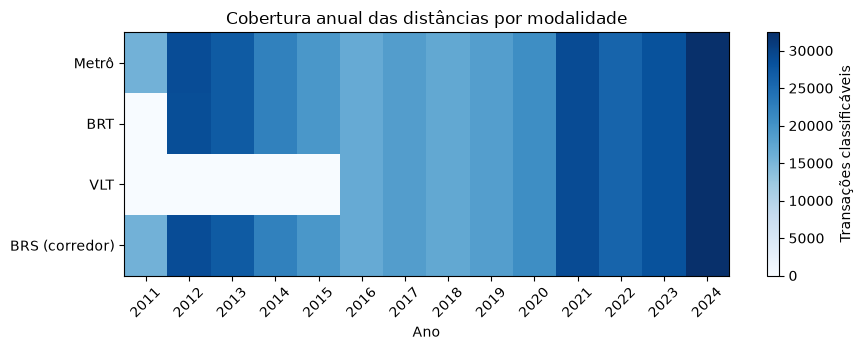

In [6]:
import matplotlib.pyplot as plt
evolucao,cobertura_anual=evolucao_proximidade(dados)
figura_proximidade(evolucao)
plt.show()
mat = cobertura_anual.apply(pd.to_numeric, errors="coerce")
fig, ax = plt.subplots(figsize=(9,3.6))
im = ax.imshow(mat.T, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(mat.columns)), mat.columns)
ax.set_xticks(range(len(mat.index)), mat.index.astype(str), rotation=45)
ax.set(xlabel="Ano", title="Cobertura anual das distâncias por modalidade")
fig.colorbar(im, ax=ax, label="Transações classificáveis"); fig.tight_layout(); plt.show()

## 5. Limitações do diagnóstico

A distância reta é mantida para auditoria e não responde à solicitação de acesso a pé. A análise de caminhada abaixo usa rede contemporânea e cronologia conservadora com registros de incerteza. O artigo explicita cobertura por bairro, por AP e por modalidade.

## 6. Integração dos percursos a pé

Os percursos a pé já estão calculados em `data/processed/itbi_com_caminhada.csv.gz`, incluído na entrega. A execução padrão reaproveita esse arquivo e confere IDs e coordenadas antes de combinar os dados; não faz consulta externa. A distância reta não substitui o percurso a pé.

In [7]:
caminho_walk=PASTA/'itbi_com_caminhada.csv.gz'
if not caminho_walk.is_file():
    raise FileNotFoundError('O arquivo itbi_com_caminhada.csv.gz não foi encontrado em data/processed/. A distância reta não substitui o percurso a pé.')
walk=pd.read_csv(caminho_walk,low_memory=False)
assert walk.id_transacao.is_unique and set(walk.id_transacao)==set(itbi_com_distancias.id_transacao)
ordem=walk.set_index('id_transacao').loc[itbi_com_distancias.id_transacao]
for coluna in ['lat_analise','lon_analise']:
    np.testing.assert_allclose(ordem[coluna].to_numpy(),itbi_com_distancias[coluna].to_numpy(),rtol=0,atol=1e-10)
extras=[c for c in walk if c.startswith(('dist_walk_','status_walk_','conector_'))]
atual=itbi_com_distancias.merge(walk[['id_transacao',*extras]],on='id_transacao',validate='one_to_one')
atual.to_csv(caminho_walk,index=False)
from analises_territoriais import filtro_precos,preparar_territorios,MODAIS_CAMINHADA,mascara_distancia
amostra_walk=preparar_territorios(atual.loc[filtro_precos(atual)].copy())
display(pd.DataFrame({m:{'Com percurso':amostra_walk[c].notna().sum(),'Classificáveis a 800 m':mascara_distancia(amostra_walk,c,800).sum()} for m,c in MODAIS_CAMINHADA.items()}).T)
print('Perguntas territoriais e de transporte: executar 05_artigo.ipynb.')

,Com percurso,Classificáveis a 800 m
Metrô,301894,280192
BRT,266878,264887
VLT,178976,178593


Perguntas territoriais e de transporte: executar 05_artigo.ipynb.


## 7. Referência comum de 2024 — quatro modalidades

O arquivo acesso_2024_caminhada.csv.gz reúne percursos até os acessos das quatro modalidades no recorte de 2024, incluindo 255 pontos BRS do GTFS SMTR de abril de 2024. As ruas e entradas OSM de 2026 são uma aproximação espacial, sem reconstrução diária. A execução padrão confere as coordenadas e reutiliza os percursos incluídos na entrega; não consulta serviços externos.

In [8]:
ref_2024=pd.read_csv(PASTA/'acesso_2024_caminhada.csv.gz')
assert ref_2024.id_grupo_geografico.is_unique
atuais=itbi[['id_grupo_geografico','lat_analise','lon_analise']].drop_duplicates('id_grupo_geografico')
coord=ref_2024.set_index('id_grupo_geografico').loc[atuais.id_grupo_geografico]
for col in ['lat_analise','lon_analise']:
    np.testing.assert_allclose(coord[col].to_numpy(),atuais[col].to_numpy(),rtol=0,atol=1e-10)
from descritiva_proposta import MODAIS
assert set(MODAIS)=={'Metrô','BRT','VLT','BRS'}
display(pd.DataFrame({'Modalidade':list(MODAIS),'Locais com percurso':[ref_2024[c].notna().sum() for c in MODAIS.values()]}))
print('Referência espacial de 2024 conferida.')

,Modalidade,Locais com percurso
0,Metrô,56870
1,BRT,60489
2,VLT,56870
3,BRS,56887


Referência espacial de 2024 conferida.


## 8. Distância Manhattan e percurso a pé

Para cada local, calculamos a menor soma dos deslocamentos leste–oeste e norte–sul até um dos acessos. As coordenadas estão em metros, na projeção UTM 23S. O ponto mais próximo pode mudar de uma medida para outra. Comparamos as duas na amostra que tem classificação de percurso válida em cada modalidade.

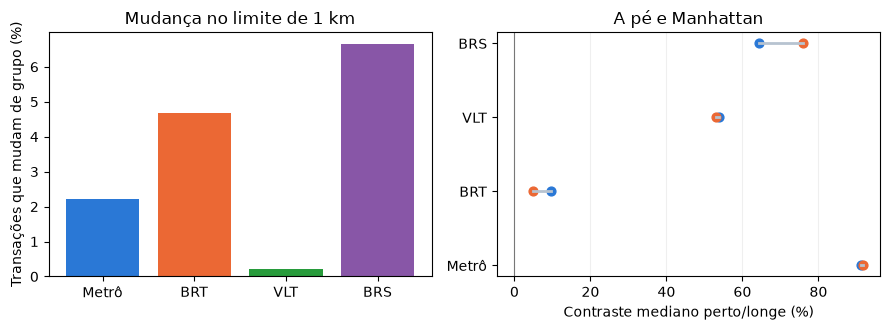

In [9]:
import matplotlib.pyplot as plt
from preco_por_distancia import distancias_manhattan, comparar_metricas
from descritiva_proposta import LIMITE_PERTO, carregar_e_analisar

base_2024 = carregar_e_analisar()["amostra_2024"]
manhattan = distancias_manhattan(base_2024)
assert manhattan.index.is_unique and manhattan.ge(0).all().all()
comparacao = comparar_metricas(base_2024, manhattan, LIMITE_PERTO)
fig, axs = plt.subplots(1,2,figsize=(9,3.4))
modal = comparacao.index.tolist(); x = np.arange(len(modal))
axs[0].bar(modal, comparacao.mudam_pct, color=["#2a78d6","#eb6834","#279b3b","#8856a7"][:len(modal)])
axs[0].set(ylabel="Transações que mudam de grupo (%)", title="Mudança no limite de 1 km")
for j, (_, r) in enumerate(comparacao.iterrows()):
    axs[1].plot([r.dif_mediana_pe_pct,r.dif_mediana_manhattan_pct],[j,j],color="#b7c3d0",lw=2)
    axs[1].scatter(r.dif_mediana_pe_pct,j,color="#2a78d6",s=40)
    axs[1].scatter(r.dif_mediana_manhattan_pct,j,color="#eb6834",s=40)
axs[1].axvline(0,color="#777",lw=.8); axs[1].set_yticks(x,modal)
axs[1].set(xlabel="Contraste mediano perto/longe (%)", title="A pé e Manhattan")
axs[1].grid(axis="x",alpha=.2); fig.tight_layout(); plt.show()
comparacao.to_csv(PASTA/"comparacao_manhattan.csv")